![clothing_classification](clothing_classification.png)


Fashion Forward is a new AI-based e-commerce clothing retailer.
They want to use image classification to automatically categorize new product listings, making it easier for customers to find what they're looking for. It will also assist in inventory management by quickly sorting items.

As a data scientist tasked with implementing a garment classifier, your primary objective is to develop a machine learning model capable of accurately categorizing images of clothing items into distinct garment types such as shirts, trousers, shoes, etc.

In [23]:
# Run the cells below first

In [2]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchmetrics import Accuracy, Precision, Recall

import matplotlib.pyplot as plt
import random

In [3]:
# Load datasets
from torchvision import datasets
import torchvision.transforms as transforms

train_data = datasets.FashionMNIST(root='./data', train=True, download=True, transform=transforms.ToTensor())
test_data = datasets.FashionMNIST(root='./data', train=False, download=True, transform=transforms.ToTensor())

In [26]:
print("Number of Images:" ,len(train_data))
print("Testing data", len(test_data))
image, label = train_data[0]
print(type(image))     
print(image.size())
print(label)

Number of Images: 60000
Testing data 10000
<class 'torch.Tensor'>
torch.Size([1, 28, 28])
9


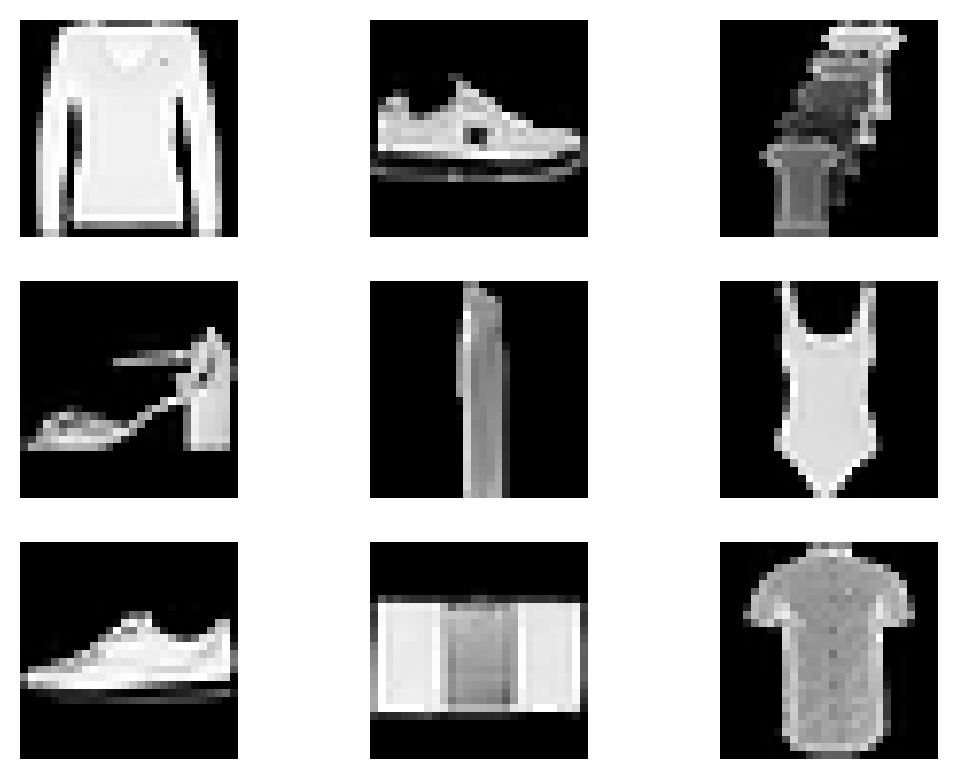

In [17]:
def random_images(images_number, train_data):
    random_indices = random.sample(range(len(train_data)), images_number)

    for i, idx in enumerate(random_indices):
        image, label = train_data[idx]
        plt.subplot(3, 3, i + 1)
        plt.imshow(image.squeeze(0), cmap="gray")
        plt.axis("off")

    plt.show()

random_images(9, train_data)

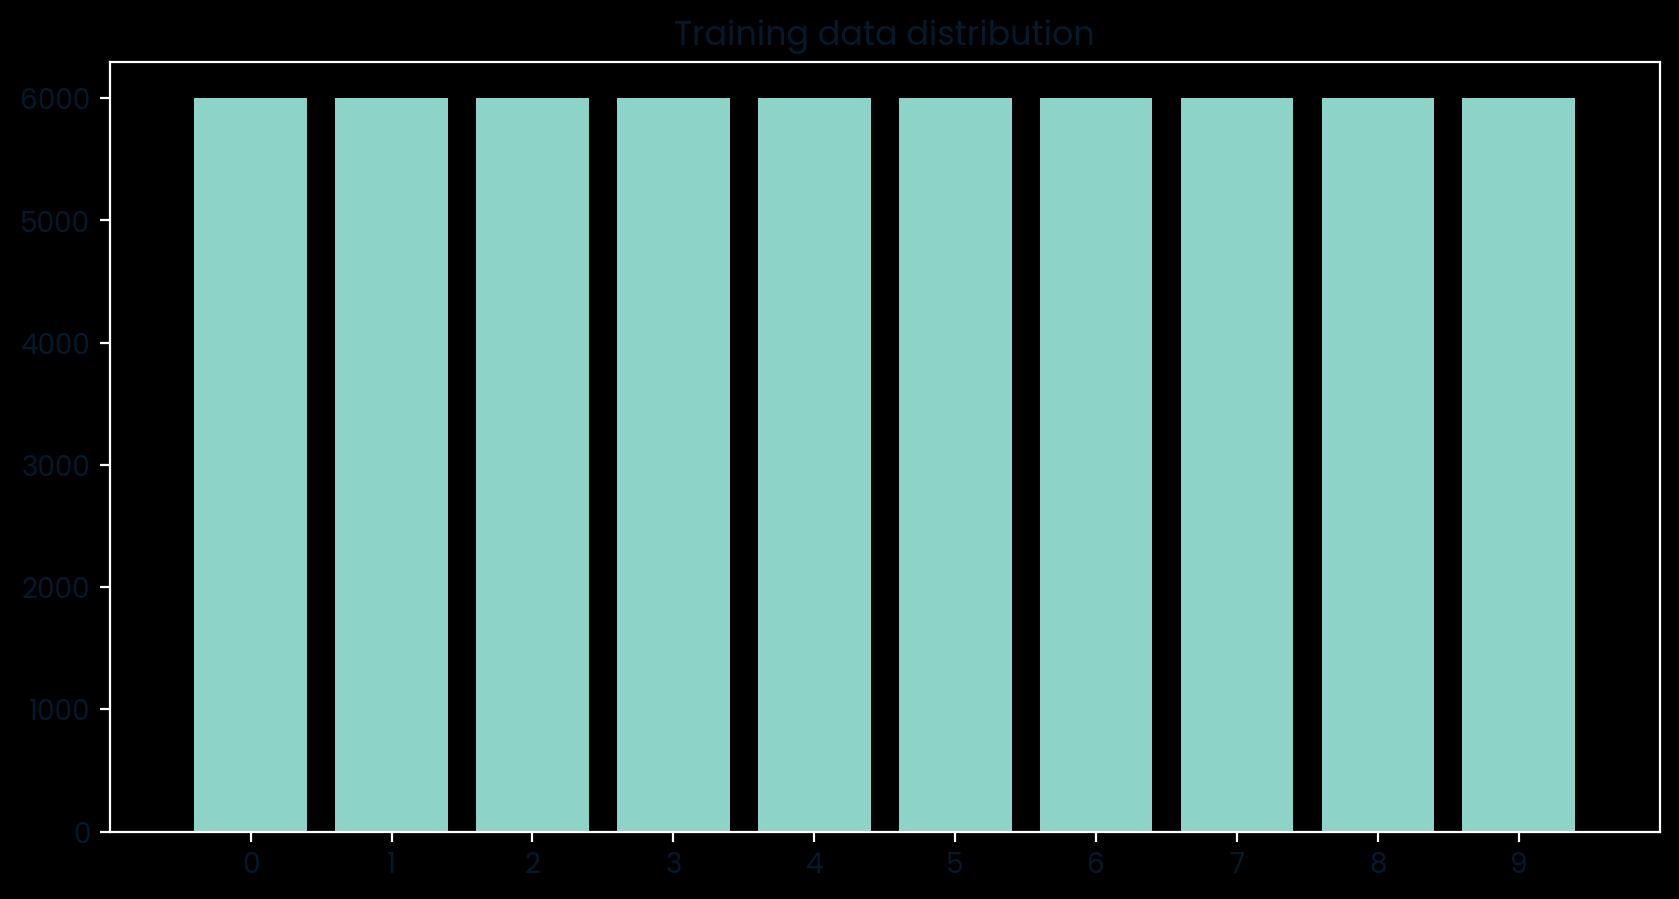

In [41]:
import numpy as np
import matplotlib.pyplot as plt  

def plot_labels_distribution(labels):
    counts = np.bincount(labels)
    plt.style.use('dark_background')
    fig, ax = plt.subplots(figsize=(10,5))
    ax.bar(range(10), counts, width=0.8, align='center')
    ax.set(xticks=range(10), xlim=[-1, 10], title='Training data distribution')
    plt.show()

all_labels = [label for _, label in train_data]
plot_labels_distribution(all_labels)

In [35]:

class Net(nn.Module):
    def __init__(self,num_classes):
        super().__init__()
        self.feature_extractor = nn.Sequential(
        nn.Conv2d(1, 32, kernel_size=3, padding=1),
        nn.ELU(),
        nn.MaxPool2d(2), 
        nn.Conv2d(32, 64, kernel_size=3, padding=1),
        nn.ELU(),
        nn.Conv2d(64, 64, kernel_size=3, padding=1),
        nn.ELU(),
        nn.MaxPool2d(2),

        nn.Flatten(),
        )
        self.classifier = nn.Linear(64 * 7 * 7, num_classes)
      
    def forward (self,x):
        x = self.feature_extractor(x)
        x = self.classifier(x)
        return x 

In [36]:
from torch.utils.data import DataLoader
import torch.nn as nn
import torch.optim as optim

train_loader = DataLoader(train_data, batch_size=32, shuffle=True)

net = Net(num_classes=len(train_data.classes))

criterion = nn.CrossEntropyLoss() 
optimizer = optim.Adam(net.parameters(), lr=0.001) 

for epoch in range(10):
    total_loss = 0.0
    total_samples = 0

    for images, labels in train_loader:
        optimizer.zero_grad()
        outputs = net(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        total_samples += batch_size

    epoch_loss = total_loss / total_samples
    print(f"Epoch {epoch + 1}/10 | Ortalama train loss: {epoch_loss:.4f}")

Epoch 1/10 | Ortalama train loss: 0.3985
Epoch 2/10 | Ortalama train loss: 0.2855
Epoch 3/10 | Ortalama train loss: 0.2486
Epoch 4/10 | Ortalama train loss: 0.2209
Epoch 5/10 | Ortalama train loss: 0.1981
Epoch 6/10 | Ortalama train loss: 0.1779
Epoch 7/10 | Ortalama train loss: 0.1613
Epoch 8/10 | Ortalama train loss: 0.1450
Epoch 9/10 | Ortalama train loss: 0.1346
Epoch 10/10 | Ortalama train loss: 0.1267


In [37]:
import torch
from torch.utils.data import DataLoader
from torchmetrics import Accuracy, Precision, Recall

test_loader = DataLoader(test_data, batch_size=32, shuffle=False)

num_classes = len(test_data.classes)
device = next(net.parameters()).device

metric_accuracy = Accuracy(task="multiclass", num_classes=num_classes, average="micro").to(device)

metric_precision = Precision(task="multiclass", num_classes=num_classes, average="macro").to(device)

metric_recall = Recall(task="multiclass", num_classes=num_classes, average="macro").to(device)

predicted_categories = []

net.eval()
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = net(images)
        _, preds = torch.max(outputs, 1)

        for class_id in preds.tolist():
            predicted_categories.append(test_data.classes[class_id])

        metric_accuracy(preds, labels)
        metric_precision(preds, labels)
        metric_recall(preds, labels)

accuracy = metric_accuracy.compute().item()
precision = metric_precision.compute().item()
recall = metric_recall.compute().item()

print("First 10 predictions:", predicted_categories[:10])
print(f"Accuracy: {accuracy:.2%}")
print(f"Macro precision: {precision:.2%}")
print(f"Macro recall: {recall:.2%}")

First 10 predictions: ['Ankle boot', 'Pullover', 'Trouser', 'Trouser', 'Shirt', 'Trouser', 'Coat', 'Shirt', 'Sandal', 'Sneaker']
Accuracy: 90.29%
Macro precision: 90.33%
Macro recall: 90.29%


              precision    recall  f1-score   support

 T-shirt/top      0.851     0.815     0.832      1000
     Trouser      0.989     0.985     0.987      1000
    Pullover      0.810     0.881     0.844      1000
       Dress      0.918     0.875     0.896      1000
        Coat      0.814     0.894     0.852      1000
      Sandal      0.982     0.980     0.981      1000
       Shirt      0.756     0.692     0.723      1000
     Sneaker      0.964     0.963     0.963      1000
         Bag      0.988     0.976     0.982      1000
  Ankle boot      0.961     0.968     0.965      1000

    accuracy                          0.903     10000
   macro avg      0.903     0.903     0.903     10000
weighted avg      0.903     0.903     0.903     10000



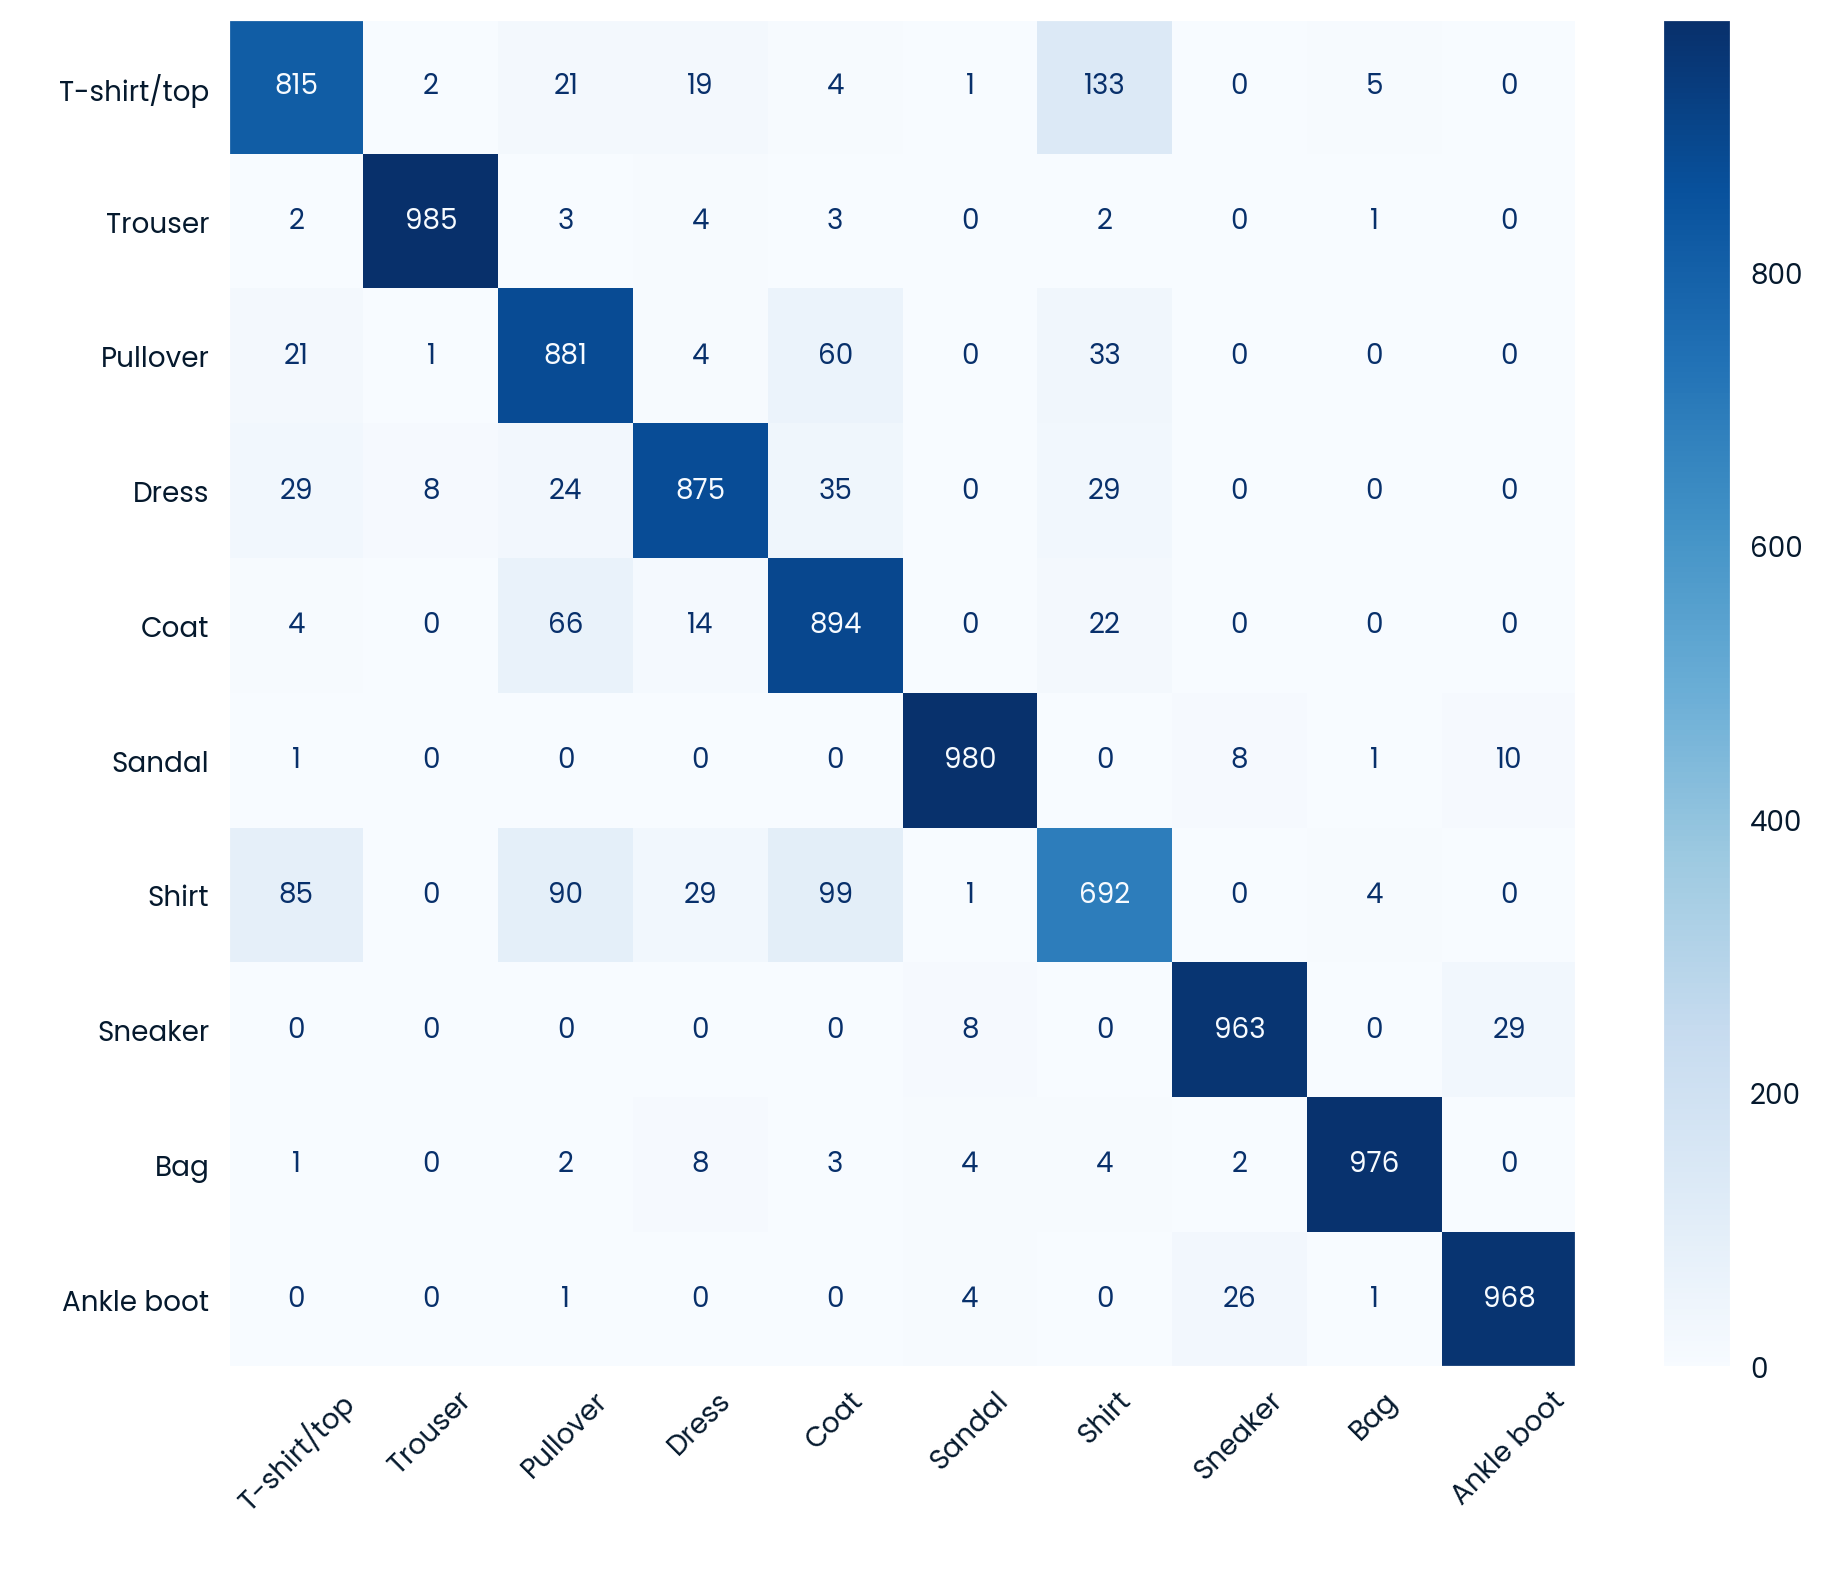

In [43]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

class_names = test_data.classes
true_categories = [class_names[label] for label in test_data.targets.tolist()]

print(classification_report(
    true_categories,
    predicted_categories,
    labels=class_names,
    digits=3,
))

fig, ax = plt.subplots(figsize=(10, 8))
fig.set_facecolor("white")

ConfusionMatrixDisplay.from_predictions(
    true_categories,
    predicted_categories,
    labels=class_names,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45,
    ax=ax,
)

plt.tight_layout()
plt.show()

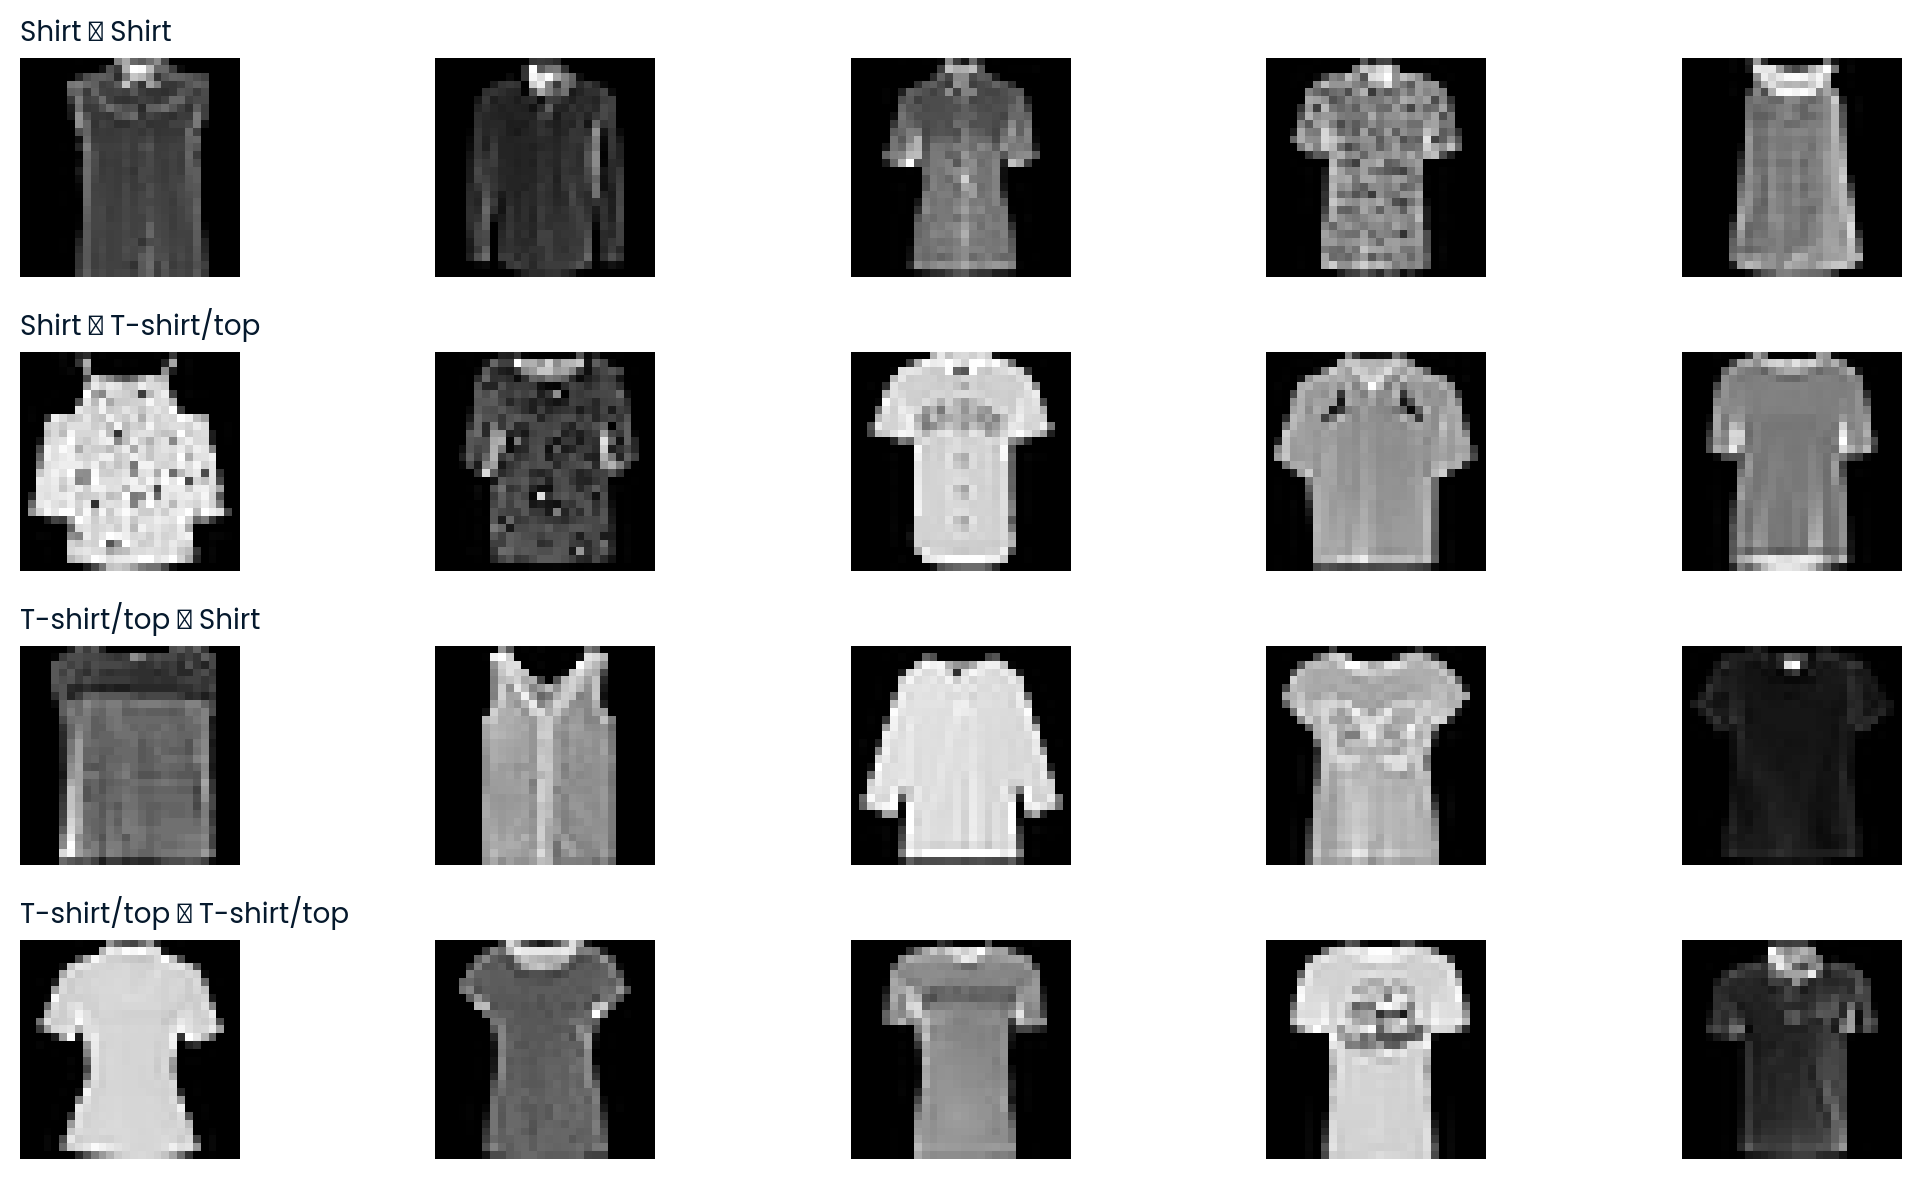

In [44]:
groups = [
    ("Shirt", "Shirt"),
    ("Shirt", "T-shirt/top"),
    ("T-shirt/top", "Shirt"),
    ("T-shirt/top", "T-shirt/top"),
]

fig, axes = plt.subplots(4, 5, figsize=(11, 6))
fig.set_facecolor("white") 

rng = random.Random(42)

for row, (actual, predicted) in zip(axes, groups):
    indices = [
        i for i, pair in enumerate(zip(true_categories, predicted_categories))
        if pair == (actual, predicted)
    ]

    row[0].set_title(f"{actual} → {predicted}", loc="left", fontsize=10)

    for ax in row:
        ax.axis("off")

    for ax, idx in zip(row, rng.sample(indices, min(5, len(indices)))):
        image, _ = test_data[idx]
        ax.imshow(image.squeeze(0), cmap="gray")

plt.tight_layout()
plt.show()